<a href="https://colab.research.google.com/github/abirbekkar/Analyse_de_donnee/blob/main/analyse_clustring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [6]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)


Saving online_shoppers_intention.csv.zip to online_shoppers_intention.csv (1).zip


In [7]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [8]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (12330, 18)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [10]:
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [11]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 125


In [12]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [13]:
# Check duplicated rows
print("Before removing duplicates:", df.shape)

# Remove duplicated rows
df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

# Check duplicates again
print("Remaining duplicates:", df.duplicated().sum())

# Check missing values again
print("\nMissing values:")
print(df.isnull().sum().sum())


Before removing duplicates: (12330, 18)
After removing duplicates: (12205, 18)
Remaining duplicates: 0

Missing values:
0


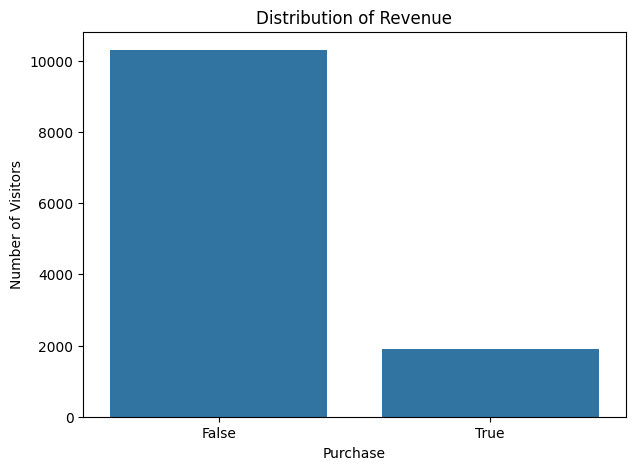

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Revenue')

plt.title('Distribution of Revenue')
plt.xlabel('Purchase')
plt.ylabel('Number of Visitors')

plt.show()

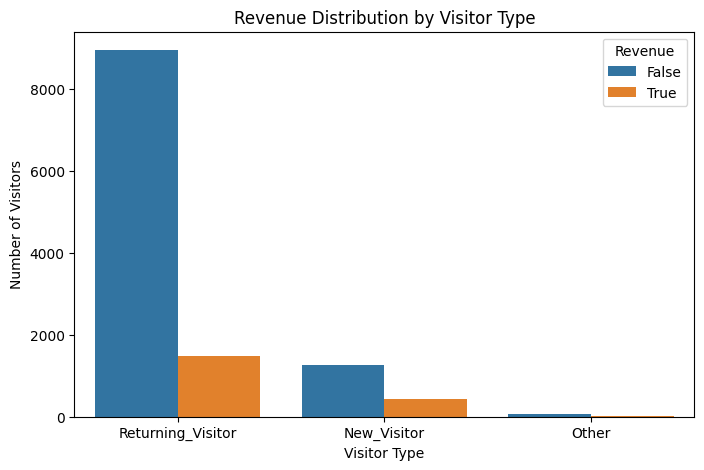

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='VisitorType', hue='Revenue')

plt.title('Revenue Distribution by Visitor Type')
plt.xlabel('Visitor Type')
plt.ylabel('Number of Visitors')

plt.show()

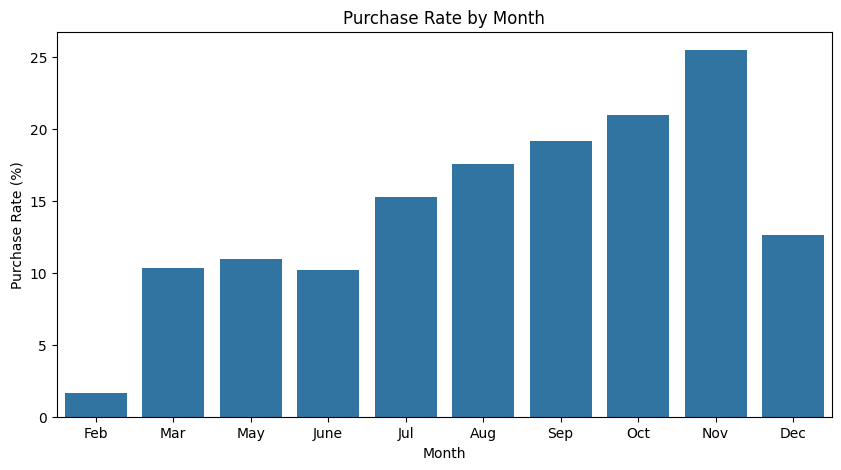

In [16]:
monthly_purchase = df.groupby('Month')['Revenue'].mean() * 100

month_order = [
    'Feb', 'Mar', 'May', 'June',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_purchase = monthly_purchase.reindex(month_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_purchase.index,
    y=monthly_purchase.values
)

plt.title('Purchase Rate by Month')
plt.xlabel('Month')
plt.ylabel('Purchase Rate (%)')

plt.show()

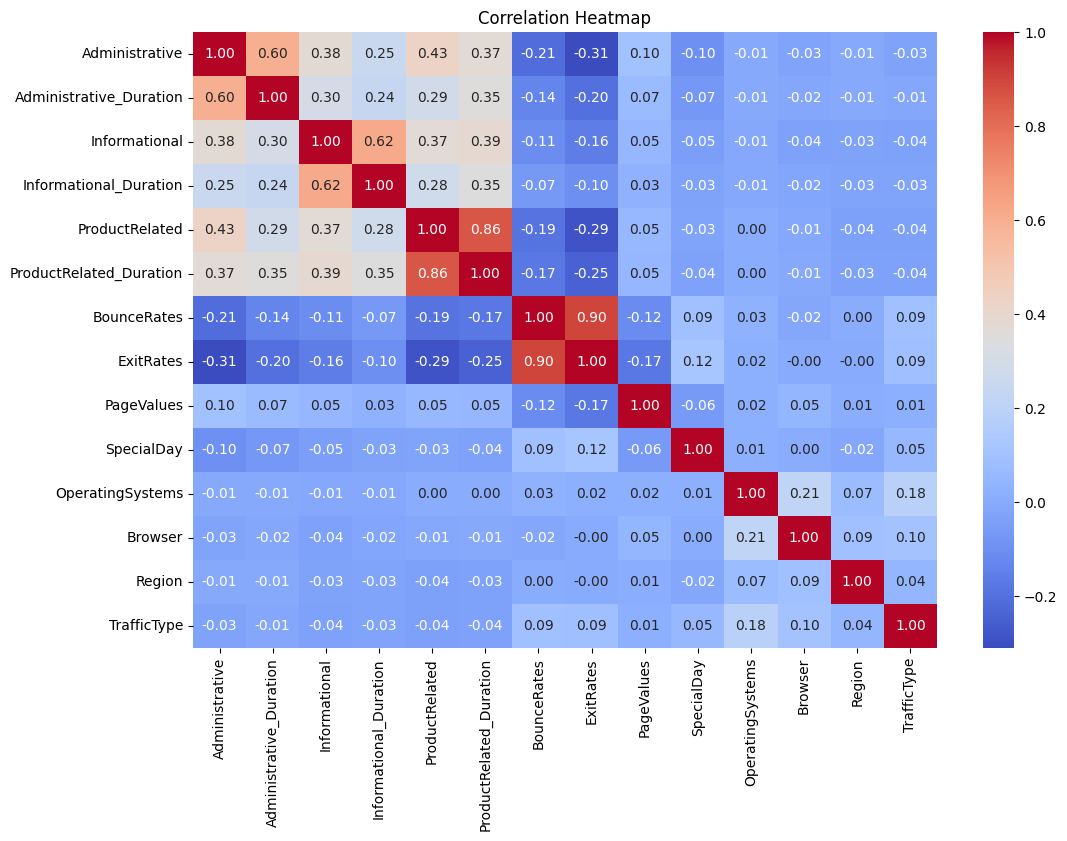

In [17]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

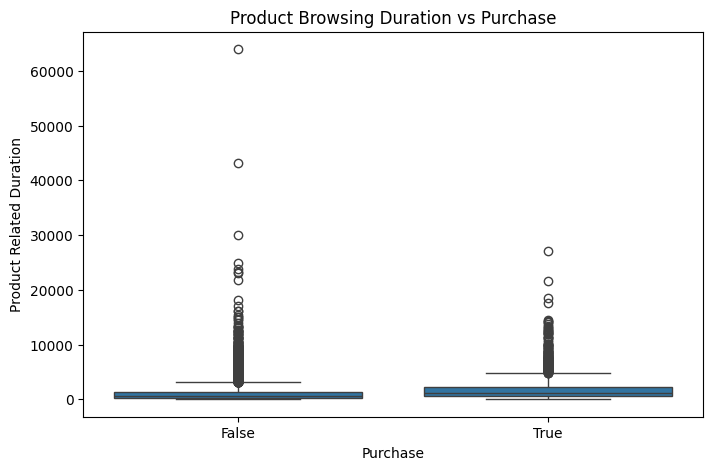

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Revenue',
    y='ProductRelated_Duration'
)

plt.title('Product Browsing Duration vs Purchase')
plt.xlabel('Purchase')
plt.ylabel('Product Related Duration')

plt.show()

In [20]:
from sklearn.preprocessing import StandardScaler

features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled.head())
print("\nMean:")
print(X_scaled.mean().round(2))

   Administrative  Administrative_Duration  Informational  \
0       -0.702302                -0.460019      -0.398824   
1       -0.702302                -0.460019      -0.398824   
2       -0.702302                -0.460019      -0.398824   
3       -0.702302                -0.460019      -0.398824   
4       -0.702302                -0.460019      -0.398824   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0               -0.246257       -0.696218                -0.628793   
1               -0.246257       -0.673793                -0.595451   
2               -0.246257       -0.696218                -0.628793   
3               -0.246257       -0.673793                -0.627404   
4               -0.246257       -0.494387                -0.301889   

   BounceRates  ExitRates  PageValues  SpecialDay  
0     3.969402   3.434394   -0.318962    -0.31024  
1    -0.450137   1.268054   -0.318962    -0.31024  
2     3.969402   3.434394   -0.318962    -0.31024  
3   

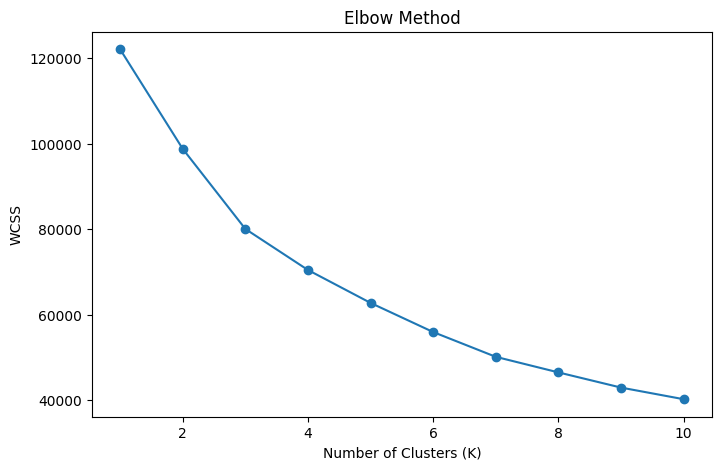

In [21]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()

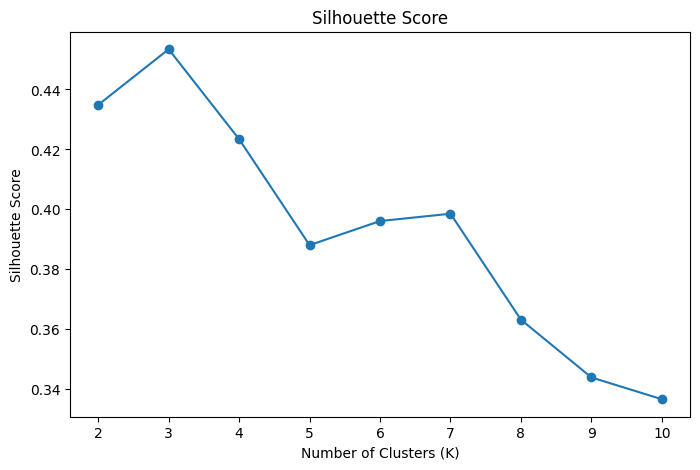

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.show()

In [23]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['Cluster']].head())

   Cluster
0        0
1        1
2        0
3        0
4        1


In [29]:
cluster_counts = df['Cluster'].value_counts().sort_index()

print(cluster_counts)

Cluster
0     932
1    9647
2    1626
Name: count, dtype: int64


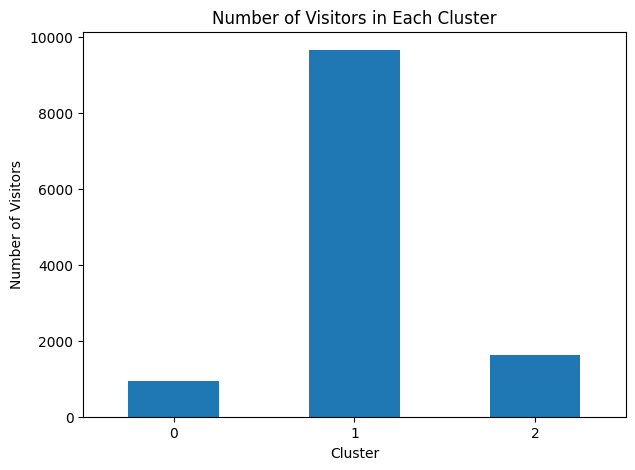

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

cluster_counts.plot(kind='bar')

plt.title('Number of Visitors in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Visitors')
plt.xticks(rotation=0)

plt.show()

In [31]:
cluster_analysis = df.groupby('Cluster')[features].mean()

print(cluster_analysis.round(2))

         Administrative  Administrative_Duration  Informational  \
Cluster                                                           
0                  0.05                     1.60           0.02   
1                  1.71                    51.22           0.22   
2                  7.38                   308.03           2.52   

         Informational_Duration  ProductRelated  ProductRelated_Duration  \
Cluster                                                                    
0                          0.10            3.36                    65.80   
1                          8.21           23.90                   874.41   
2                        212.64           96.83                  3834.25   

         BounceRates  ExitRates  PageValues  SpecialDay  
Cluster                                                  
0               0.16       0.18        0.00        0.12  
1               0.01       0.03        5.89        0.06  
2               0.01       0.02        9.73        

In [32]:
purchase_analysis = df.groupby('Cluster')['Revenue'].mean() * 100

print(purchase_analysis.round(2))

Cluster
0     0.64
1    15.03
2    27.80
Name: Revenue, dtype: float64


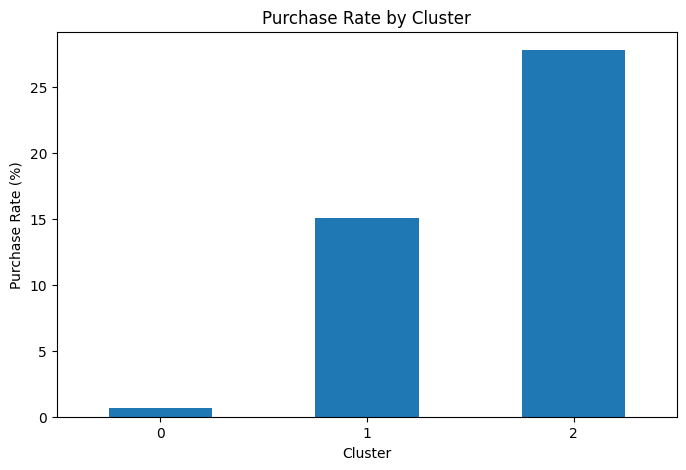

In [33]:
import matplotlib.pyplot as plt

purchase_analysis.plot(kind='bar', figsize=(8, 5))

plt.title('Purchase Rate by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=0)
plt.show()

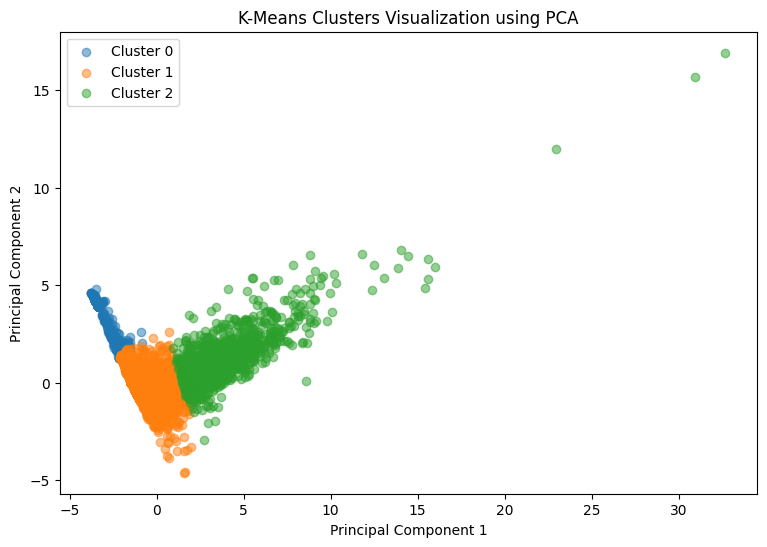

In [34]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce dimensions to 2
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = df['Cluster'].values

# Plot clusters
plt.figure(figsize=(9, 6))

for cluster in sorted(pca_df['Cluster'].unique()):
    cluster_data = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        cluster_data['PC1'],
        cluster_data['PC2'],
        label=f'Cluster {cluster}',
        alpha=0.5
    )

plt.title('K-Means Clusters Visualization using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [35]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:")
print(pca.explained_variance_ratio_.sum() * 100, "%")

Explained Variance Ratio:
[0.33759213 0.16857421]
Total Explained Variance:
50.61663430537664 %


In [36]:
# Statistical Analysis

statistical_analysis = df[features].agg([
    'mean',
    'median',
    'std',
    'var',
    'min',
    'max'
])

print(statistical_analysis.round(2))

        Administrative  Administrative_Duration  Informational  \
mean              2.34                    81.65           0.51   
median            1.00                     9.00           0.00   
std               3.33                   177.49           1.28   
var              11.09                 31503.36           1.63   
min               0.00                     0.00           0.00   
max              27.00                  3398.75          24.00   

        Informational_Duration  ProductRelated  ProductRelated_Duration  \
mean                     34.83           32.05                  1206.98   
median                    0.00           18.00                   608.94   
std                     141.42           44.59                  1919.60   
var                   20000.98         1988.59               3684869.54   
min                       0.00            0.00                     0.00   
max                    2549.38          705.00                 63973.52   

        Bou